### 1. Импорт библиотек и загрузка датасета

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('CarPrice_Assignment.csv')

print(f"Размер датасета: {df.shape[0]} строк и {df.shape[1]} признаков.")
df.head()

Размер датасета: 205 строк и 26 признаков.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

### 2. Анализ данных: пропуски и выбросы
#### 2.1. Проверка на наличие пропущенных значений (NaN)

Количество пропусков в каждом столбце:
Series([], dtype: int64)

Явных пропусков (NaN) в исходном датасете нет!


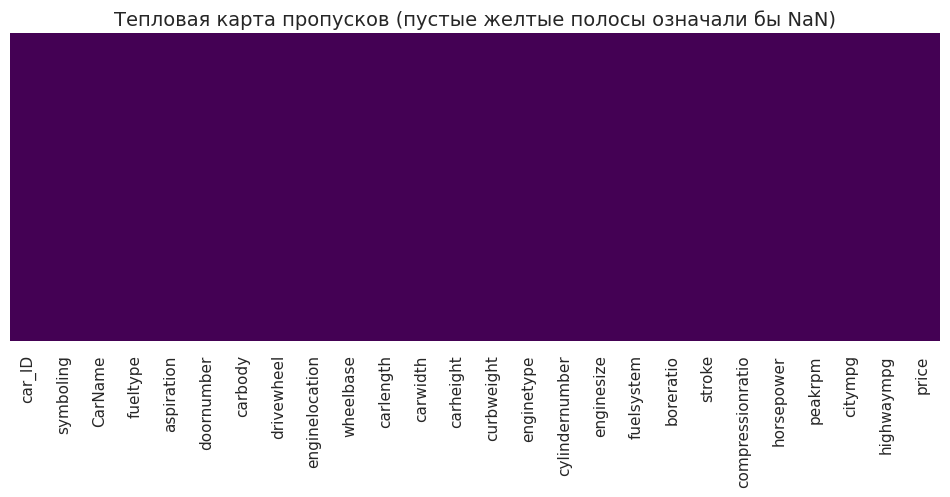

In [5]:
missing_values = df.isnull().sum()
print("Количество пропусков в каждом столбце:")
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("\nЯвных пропусков (NaN) в исходном датасете нет!")
else:
    print(f"\nВсего пропусков: {missing_values.sum()}")

plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Тепловая карта пропусков (пустые желтые полосы означали бы NaN)", fontsize=14)
plt.show()

#### 2.2. Визуализация распределения и поиск выбросов (до очистки)

Статистическое описание признаков:


,price,enginesize,horsepower
count,205.000000,205.000000,205.000000
mean,13276.710571,126.907317,104.117073
std,7988.852332,41.642693,39.544167
min,5118.000000,61.000000,48.000000
25%,7788.000000,97.000000,70.000000
50%,10295.000000,120.000000,95.000000
75%,16503.000000,141.000000,116.000000
max,45400.000000,326.000000,288.000000


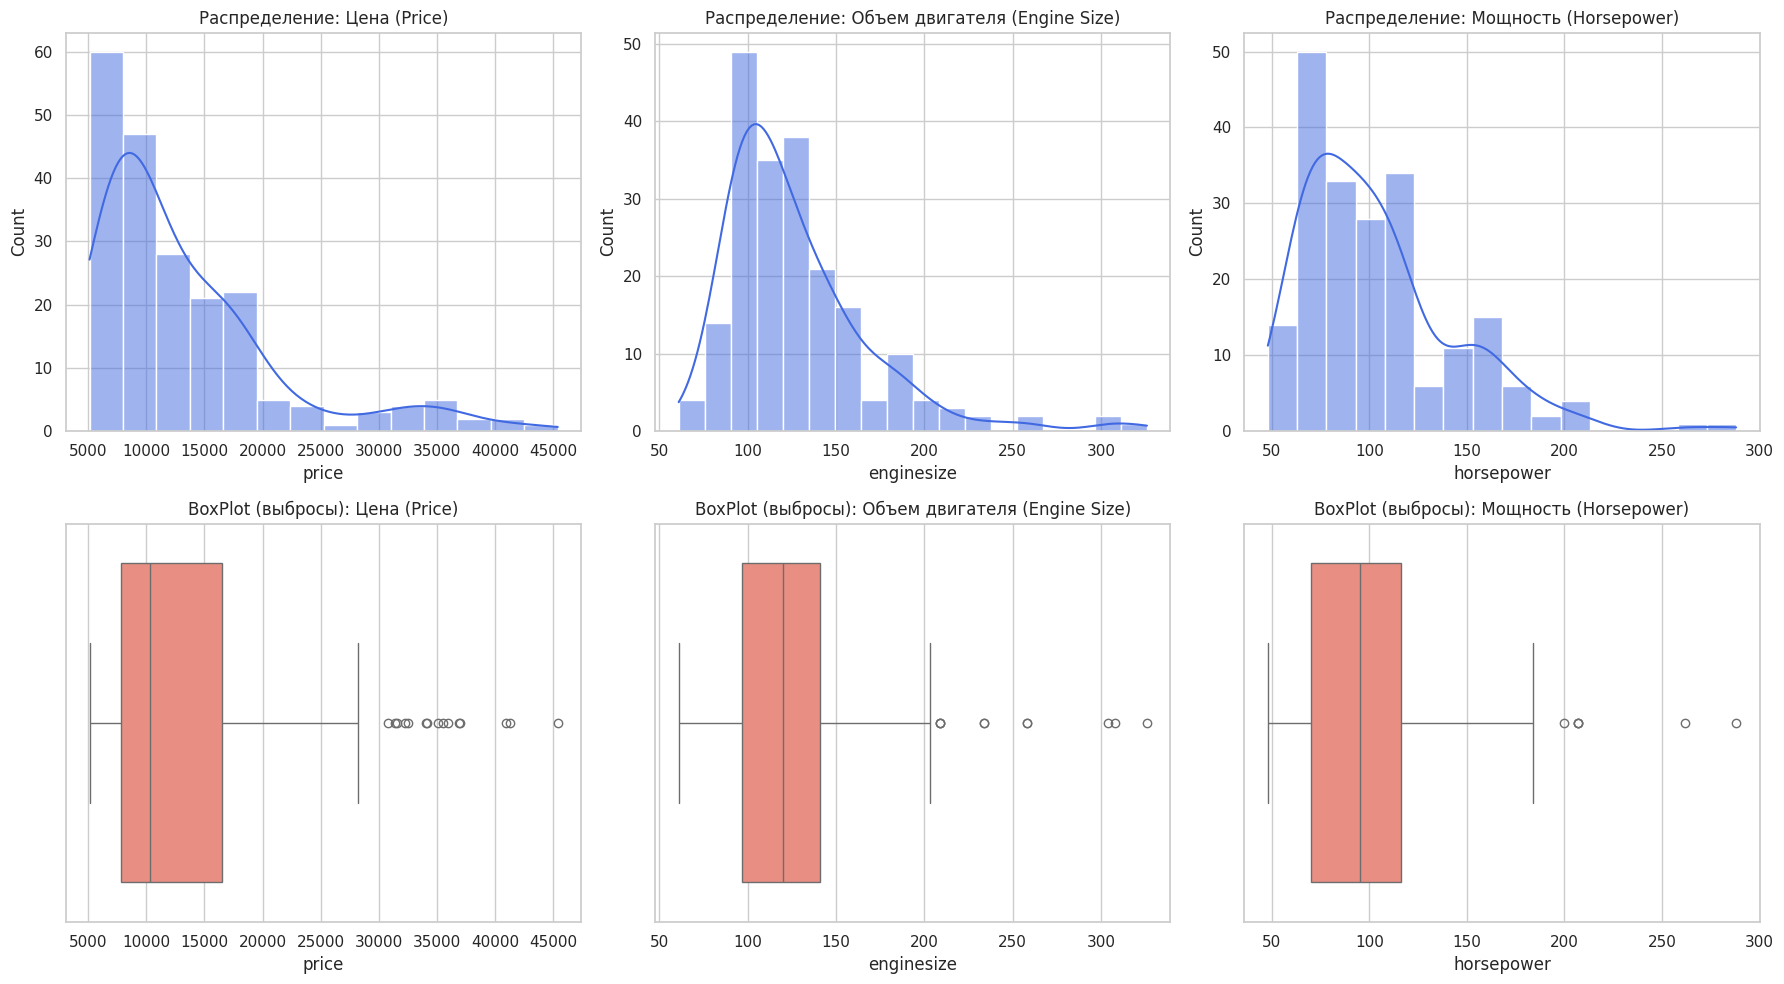

In [6]:
print("Статистическое описание признаков:")
display(df[['price', 'enginesize', 'horsepower']].describe())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

features = ['price', 'enginesize', 'horsepower']
titles = ['Цена (Price)', 'Объем двигателя (Engine Size)', 'Мощность (Horsepower)']

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color='royalblue')
    axes[0, i].set_title(f'Распределение: {titles[i]}', fontsize=12)

    sns.boxplot(x=df[col], ax=axes[1, i], color='salmon')
    axes[1, i].set_title(f'BoxPlot (выбросы): {titles[i]}', fontsize=12)

plt.tight_layout()
plt.show()

#### 2.3. Устранение выбросов методом IQR и контрольная визуализация

Строк до удаления выбросов: 205
Строк после удаления выбросов: 189
Удалено аномальных записей: 16


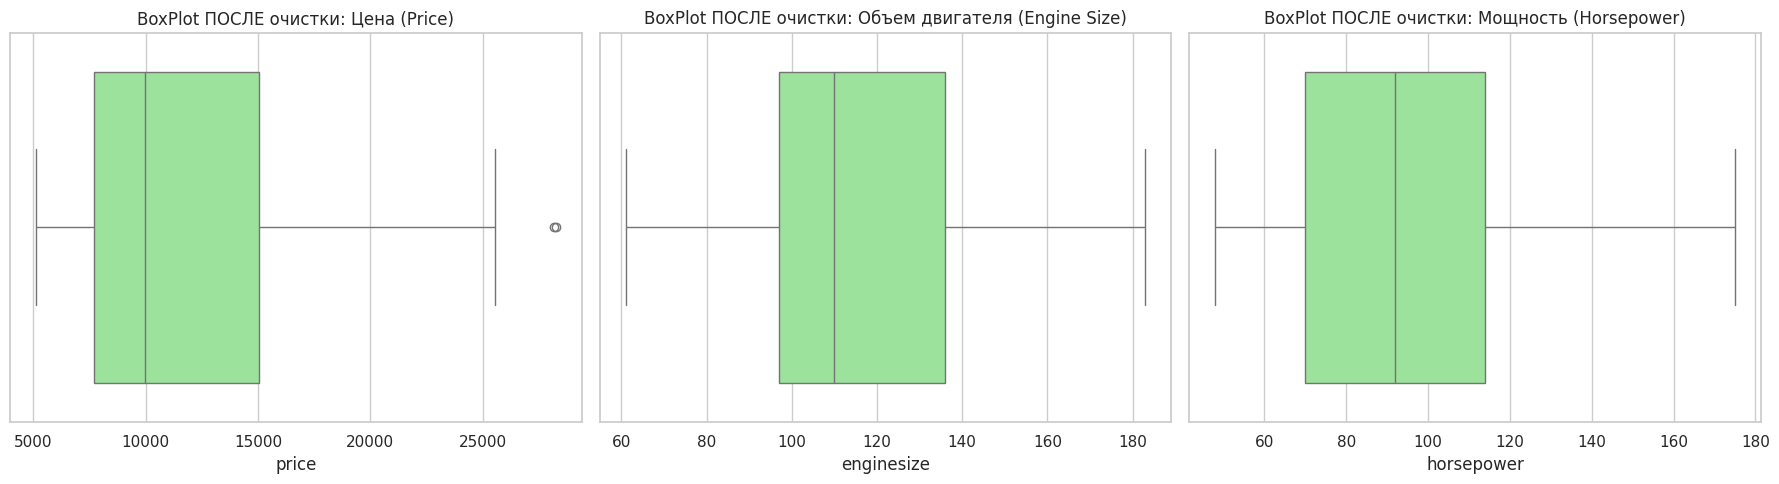

In [7]:
def remove_outliers_iqr(data, columns):
    df_clean = data.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
    return df_clean

df_cleaned = remove_outliers_iqr(df, ['price', 'enginesize', 'horsepower'])

print(f"Строк до удаления выбросов: {df.shape[0]}")
print(f"Строк после удаления выбросов: {df_cleaned.shape[0]}")
print(f"Удалено аномальных записей: {df.shape[0] - df_cleaned.shape[0]}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(features):
    sns.boxplot(x=df_cleaned[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'BoxPlot ПОСЛЕ очистки: {titles[i]}', fontsize=12)

plt.tight_layout()
plt.show()

=== АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===


/tmp/ipykernel_4987/887354970.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='drivewheel', y='price', data=df, ax=axes[2], palette='Set2')


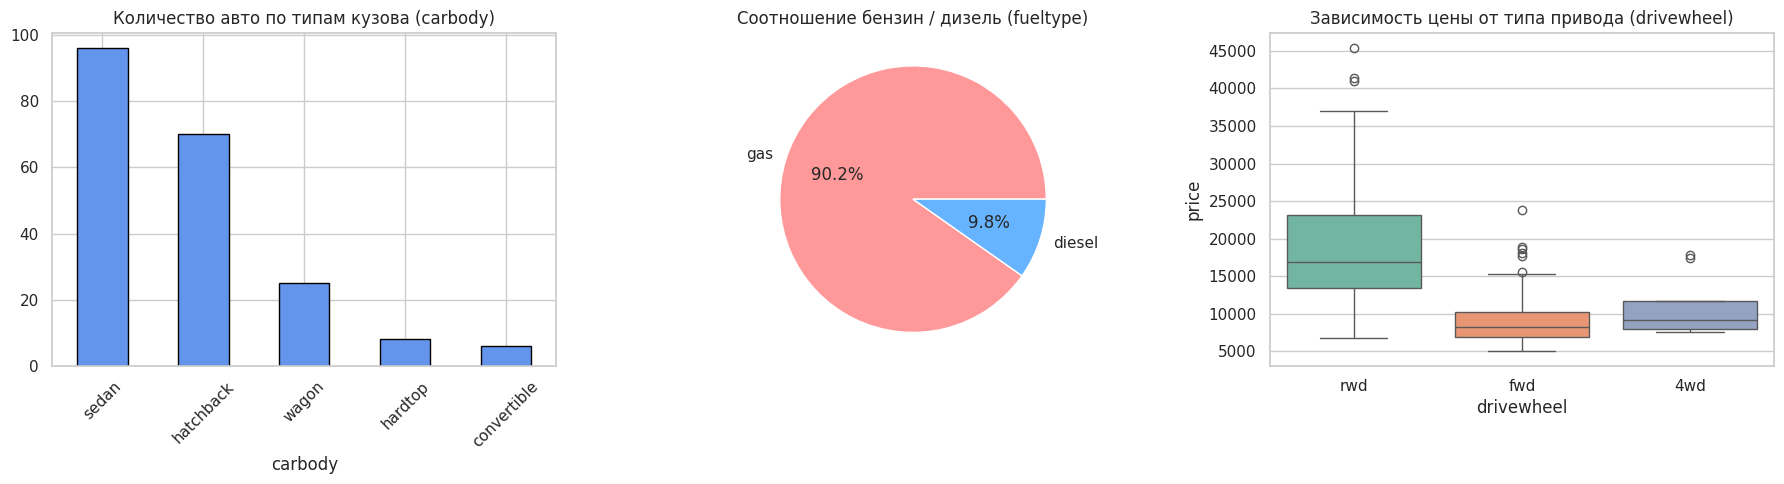

In [15]:
print("=== АНАЛИЗ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['carbody'].value_counts().plot(kind='bar', ax=axes[0], color='cornflowerblue', edgecolor='black')
axes[0].set_title('Количество авто по типам кузова (carbody)')
axes[0].tick_params(axis='x', rotation=45)

df['fueltype'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
axes[1].set_title('Соотношение бензин / дизель (fueltype)')
axes[1].set_ylabel('')

sns.boxplot(x='drivewheel', y='price', data=df, ax=axes[2], palette='Set2')
axes[2].set_title('Зависимость цены от типа привода (drivewheel)')

plt.tight_layout()
plt.show()

=== ТЕПЛОВАЯ КАРТА КОРРЕЛЯЦИЙ ЧИСЛОВЫХ ПРИЗНАКОВ ===


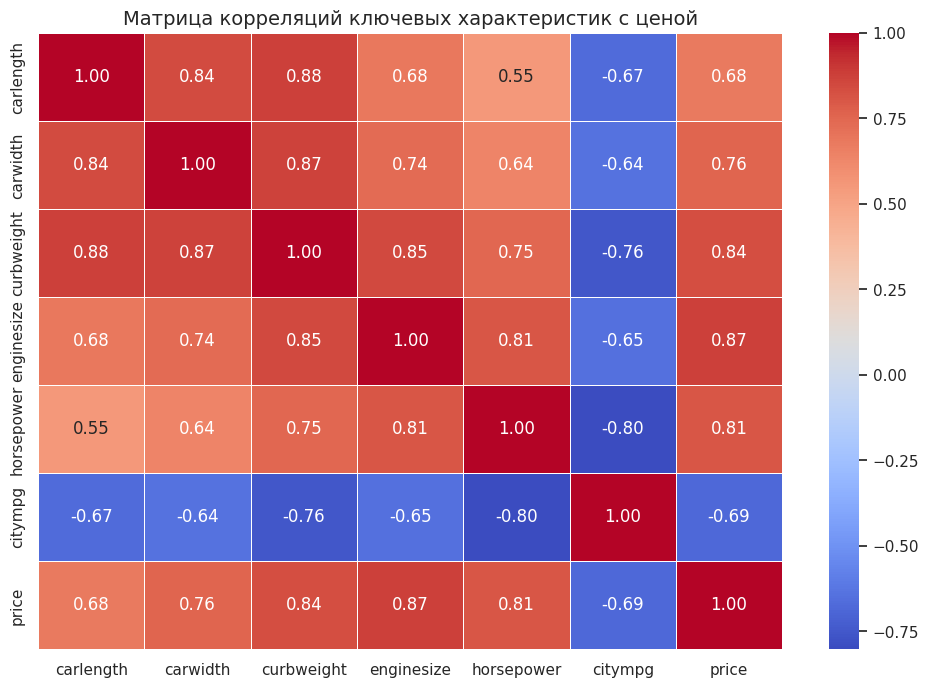

In [14]:
print("=== ТЕПЛОВАЯ КАРТА КОРРЕЛЯЦИЙ ЧИСЛОВЫХ ПРИЗНАКОВ ===")

plt.figure(figsize=(12, 8))
corr_matrix = df[['carlength', 'carwidth', 'curbweight', 'enginesize', 'horsepower', 'citympg', 'price']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Матрица корреляций ключевых характеристик с ценой', fontsize=14)
plt.show()

### 3. Генерация новых признаков (Feature Engineering)

=== ГЕНЕРАЦИЯ НОВЫХ ПРИЗНАКОВ ===
Успешно создано 5 новых признаков:


,Brand,Power_to_Weight,Avg_MPG,Is_Luxury,Door_Count_Num
0,alfa-romero,0.043564,24.0,1,2
1,alfa-romero,0.043564,24.0,1,2
2,alfa-romero,0.054552,22.5,1,2
3,audi,0.043646,27.0,1,4
4,audi,0.040722,20.0,1,4


/tmp/ipykernel_4987/2963940299.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Is_Luxury', data=df_processed, ax=axes[2], palette='pastel')


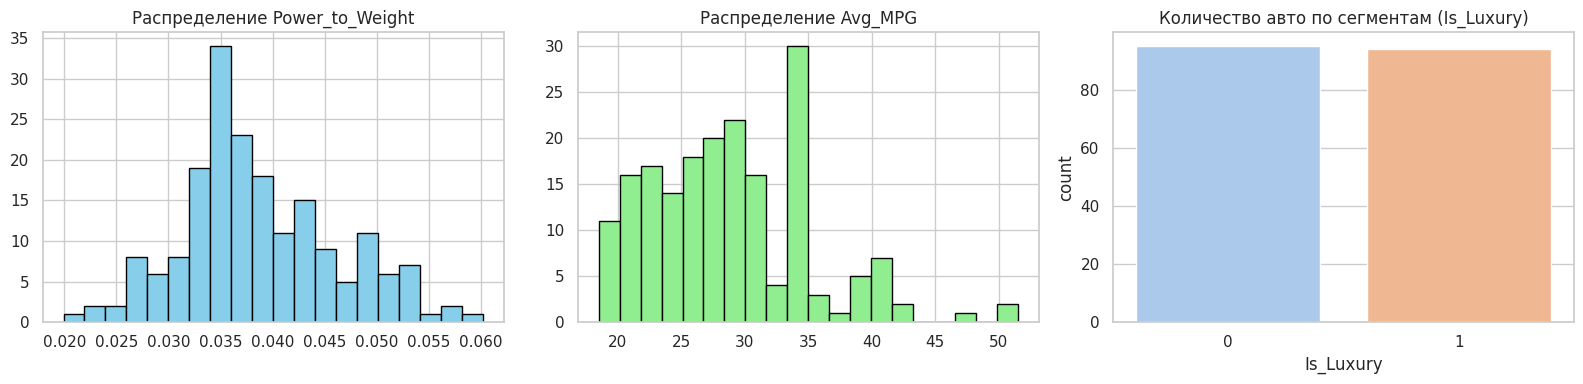

In [9]:
print("=== ГЕНЕРАЦИЯ НОВЫХ ПРИЗНАКОВ ===")

df_processed = df_cleaned.copy() if 'df_cleaned' in locals() else df.copy()

df_processed['Brand'] = df_processed['CarName'].apply(lambda x: x.split()[0].lower())
df_processed['Brand'] = df_processed['Brand'].replace({
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
})

df_processed['Power_to_Weight'] = df_processed['horsepower'] / df_processed['curbweight']

df_processed['Avg_MPG'] = (df_processed['citympg'] + df_processed['highwaympg']) / 2

price_median = df_processed['price'].median()
df_processed['Is_Luxury'] = (df_processed['price'] > price_median).astype(int)

door_map = {'two': 2, 'four': 4}
df_processed['Door_Count_Num'] = df_processed['doornumber'].map(door_map)

print(f"Успешно создано 5 новых признаков:")
new_features = ['Brand', 'Power_to_Weight', 'Avg_MPG', 'Is_Luxury', 'Door_Count_Num']
display(df_processed[new_features].head())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df_processed['Power_to_Weight'].hist(bins=20, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Распределение Power_to_Weight')

df_processed['Avg_MPG'].hist(bins=20, ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_title('Распределение Avg_MPG')

sns.countplot(x='Is_Luxury', data=df_processed, ax=axes[2], palette='pastel')
axes[2].set_title('Количество авто по сегментам (Is_Luxury)')

plt.tight_layout()
plt.show()

### 4. Кодирование категориальных признаков

In [10]:
print("=== КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===")

df_processed['Engine_Location_Rear'] = (df_processed['enginelocation'] == 'rear').astype(int)

ohe_cols = ['fueltype', 'aspiration', 'carbody', 'drivewheel']
print(f"Применяем One-Hot Encoding для признаков: {ohe_cols}")

df_encoded = pd.get_dummies(df_processed, columns=ohe_cols, drop_first=True)

cols_to_drop = ['car_ID', 'CarName', 'Brand', 'doornumber', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']
df_final = df_encoded.drop(columns=cols_to_drop)

print("\nКодирование успешно завершено!")
print(f"Размерность таблицы после кодирования: {df_final.shape[0]} строк и {df_final.shape[1]} признаков.")
print("\nПервые 5 строк подготовленного датасета:")
display(df_final.head())

=== КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ ===
Применяем One-Hot Encoding для признаков: ['fueltype', 'aspiration', 'carbody', 'drivewheel']

Кодирование успешно завершено!
Размерность таблицы после кодирования: 189 строк и 28 признаков.

Первые 5 строк подготовленного датасета:


,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,...,Door_Count_Num,Engine_Location_Rear,fueltype_gas,aspiration_turbo,carbody_hardtop,carbody_hatchback,carbody_sedan,carbody_wagon,drivewheel_fwd,drivewheel_rwd
0,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,2,0,True,False,False,False,False,False,False,True
1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,...,2,0,True,False,False,False,False,False,False,True
2,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,...,2,0,True,False,False,True,False,False,False,True
3,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,...,4,0,True,False,False,False,True,False,True,False
4,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,...,4,0,True,False,False,False,True,False,False,False


### 5. Масштабирование числовых признаков: Стандартизация и Нормализация

=== МАСШТАБИРОВАНИЕ ЧИСЛОВЫХ ПРИЗНАКОВ ===
Сравнение статистик признака 'price':


,Исходные,StandardScaler,MinMaxScaler
Среднее (Mean),11466.0697,0.0000,0.2745
Станд. откл. (Std),4945.5136,1.0027,0.2138
Минимум (Min),5118.0000,-1.2870,0.0000
Максимум (Max),28248.0000,3.4024,1.0000


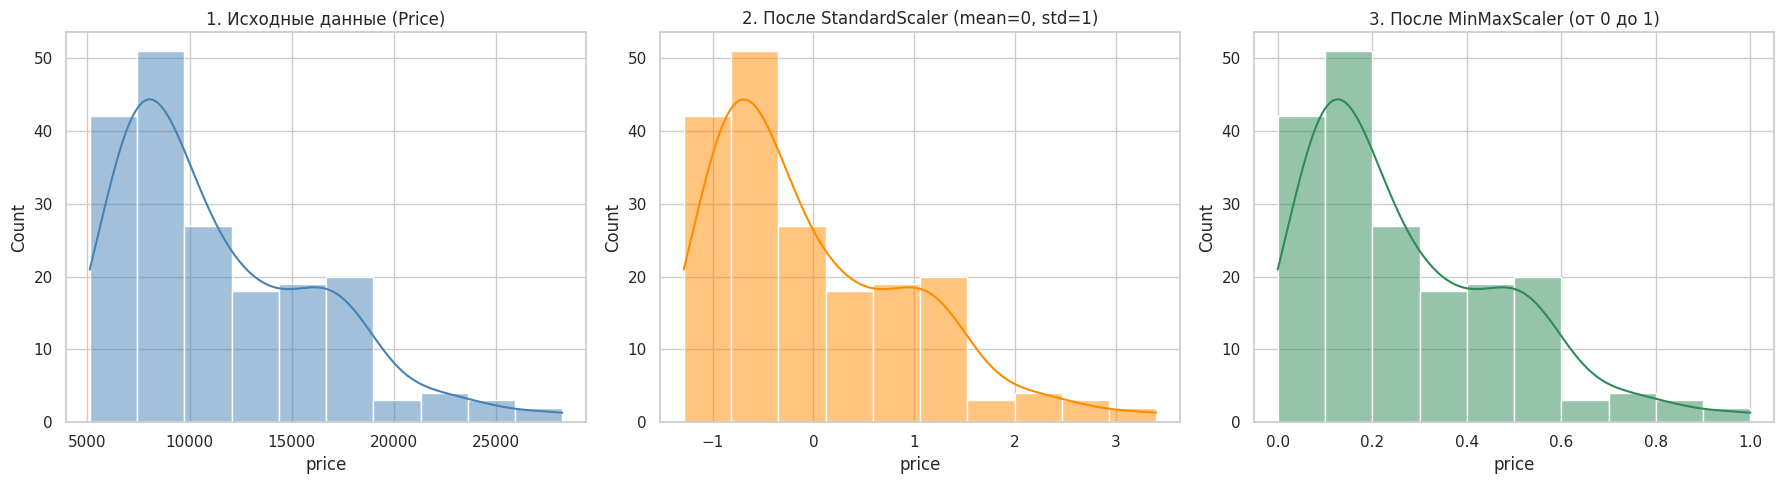

In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

print("=== МАСШТАБИРОВАНИЕ ЧИСЛОВЫХ ПРИЗНАКОВ ===")

continuous_cols = [
    'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight',
    'enginesize', 'boreratio', 'stroke', 'compressionratio',
    'horsepower', 'peakrpm', 'citympg', 'highwaympg',
    'Power_to_Weight', 'Avg_MPG', 'price'
]

scaler_std = StandardScaler()
df_standardized = df_final.copy()
df_standardized[continuous_cols] = scaler_std.fit_transform(df_standardized[continuous_cols])

scaler_minmax = MinMaxScaler()
df_normalized = df_final.copy()
df_normalized[continuous_cols] = scaler_minmax.fit_transform(df_normalized[continuous_cols])

stats_comparison = pd.DataFrame({
    'Исходные': [df_final['price'].mean(), df_final['price'].std(), df_final['price'].min(), df_final['price'].max()],
    'StandardScaler': [df_standardized['price'].mean(), df_standardized['price'].std(), df_standardized['price'].min(), df_standardized['price'].max()],
    'MinMaxScaler': [df_normalized['price'].mean(), df_normalized['price'].std(), df_normalized['price'].min(), df_normalized['price'].max()]
}, index=['Среднее (Mean)', 'Станд. откл. (Std)', 'Минимум (Min)', 'Максимум (Max)'])

print("Сравнение статистик признака 'price':")
display(stats_comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_final['price'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('1. Исходные данные (Price)')

sns.histplot(df_standardized['price'], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('2. После StandardScaler (mean=0, std=1)')

sns.histplot(df_normalized['price'], kde=True, ax=axes[2], color='seagreen')
axes[2].set_title('3. После MinMaxScaler (от 0 до 1)')

plt.tight_layout()
plt.show()

### 6. Сохранение обработанных данных

In [12]:
df_standardized.to_csv('car_price_standardized.csv', index=False)
df_normalized.to_csv('car_price_normalized.csv', index=False)

print("Обработанные датасеты успешно сохранены:")
print("1. car_price_standardized.csv (стандартизированные данные)")
print("2. car_price_normalized.csv (нормализованные данные)")

Обработанные датасеты успешно сохранены:
1. car_price_standardized.csv (стандартизированные данные)
2. car_price_normalized.csv (нормализованные данные)
